# Proteome recovery

Paired CAMP/BindSite maximum S/T-site scores on the same 19,218 sequence-matched proteins. Fifty of 53 original positive accessions map to this comparison. Unknown background is unlabeled.

All figures are saved as SVG (editable text), PNG and PDF in `benchmarks/figures/`.


In [1]:
# Load paired protein scores
from pathlib import Path
import sys
ROOT = Path.cwd()
assert (ROOT / "benchmarks" / "analysis.py").is_file(), "Run this notebook from the repository root."
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from benchmarks.analysis import proteome_recovery, save_tables
from benchmarks.plot_figures import plot_recovery
import matplotlib.pyplot as plt
DATA, RESULTS, FIGURES = [ROOT / "benchmarks" / name for name in ["data", "results", "figures"]]
proteins = pd.read_csv(DATA / "proteins.csv")
display(pd.DataFrame({"ranked_proteins": [len(proteins)], "known_clients": [proteins.is_known_binder.sum()]}))


,ranked_proteins,known_clients
0,19218,50


## 1. Known-client recovery

Average tied cutoffs. Compare with 2,000 reference sets matched for protein length and S/T count (seed 20261026). These comparisons to random are exploratory.


In [2]:
# Recalculate ranking and recovery
recovery, curves, rankings = proteome_recovery(proteins)
save_tables(RESULTS, recovery_at_K=recovery, recovery_curve=curves, protein_rankings=rankings)
display(recovery[["model", "top_K", "tie_averaged_known_hits", "recall", "matched_random_mean"]].round(3))


,model,top_K,tie_averaged_known_hits,recall,matched_random_mean
0,CAMP,100,5.0,0.10,0.424
1,CAMP,500,9.0,0.18,2.110
2,CAMP,1000,18.0,0.36,4.112
3,BindSite,100,1.0,0.02,0.384
4,BindSite,500,7.0,0.14,2.024
5,BindSite,1000,11.0,0.22,4.100


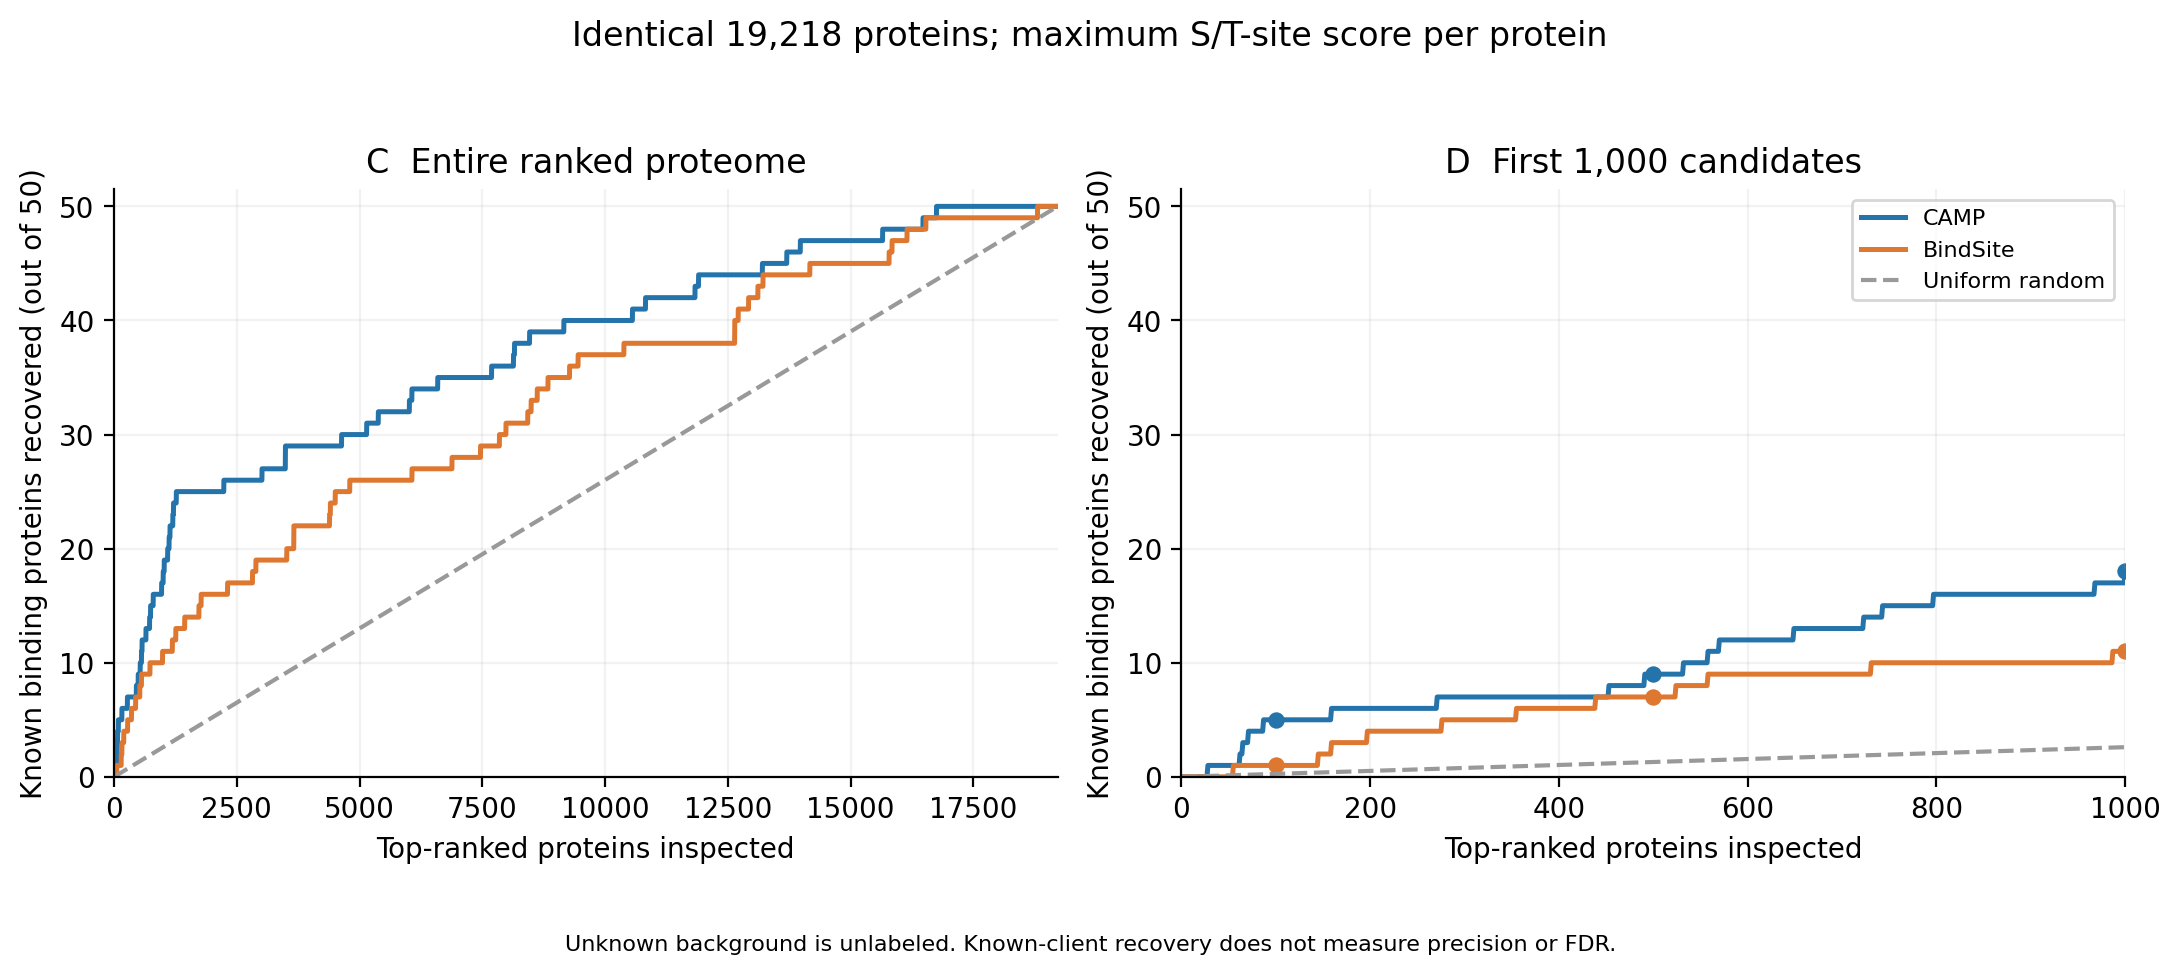

In [3]:
# Figure 6C–D: full ranking and first 1,000 proteins
plt.close(plot_recovery(recovery, curves, FIGURES))
display(Image(filename=str(FIGURES / "Figure6CD_proteome_recovery.png")))


## 2. Known accessions and exclusions

Recovery of known clients measures prioritization. It does not label the remaining proteins as negative or estimate precision/FDR. Full sequences were used for the recorded inference; no length-dependent truncation was applied.


In [4]:
# Inspect known-client ranks
known = rankings.loc[rankings.is_known_binder == 1]
display(known.pivot(index="accession", columns="model", values="rank_min").sort_values("CAMP").head(15))
display(pd.read_csv(DATA / "known_clients.csv").loc[lambda frame: frame.included_in_comparison == 0])


model,BindSite,CAMP
accession,,
Q6P4D5,159,28
Q9NQT8,55,62
Q96JI7,7848,65
P55042,1257,71
O75628,439,87
Q12809,524,159
Q9P286,731,271
P49685,355,453
Q96AD5,197,491


,uniprot_id,n_known_positive_sites,sample_ids,status,included_in_comparison
18,Q05086-2,1,camp_row_2393,isoform_evidence_not_transferred_to_canonical,0
40,Q96RK0-2,1,camp_row_2366,isoform_evidence_not_transferred_to_canonical,0
46,Q9NS23-2,2,camp_row_2501;camp_row_2502,isoform_evidence_not_transferred_to_canonical,0
